Dataset Completo - Média (petal_length): 3.758
Dataset Completo - Desvio Padrão (petal_length): 1.765

Estatísticas por Espécie:
             mean       std
species                    
setosa      1.462  0.173664
versicolor  4.260  0.469911
virginica   5.552  0.551895


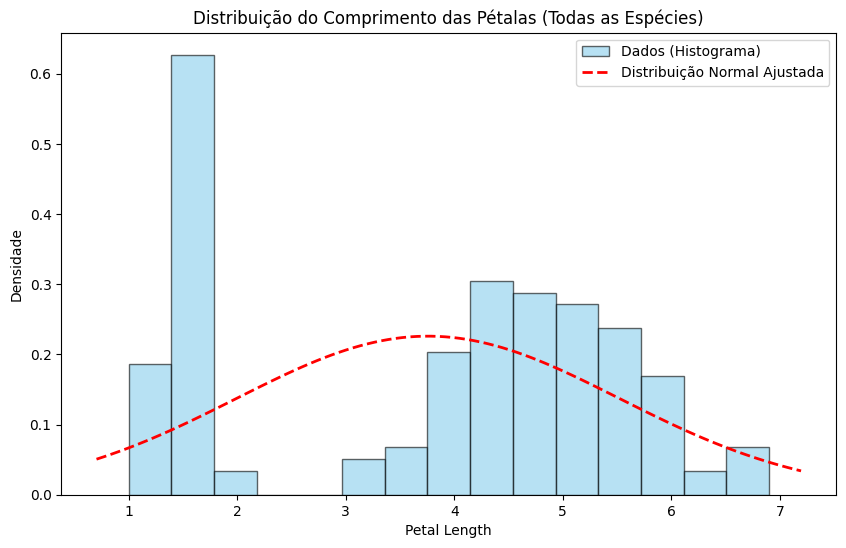

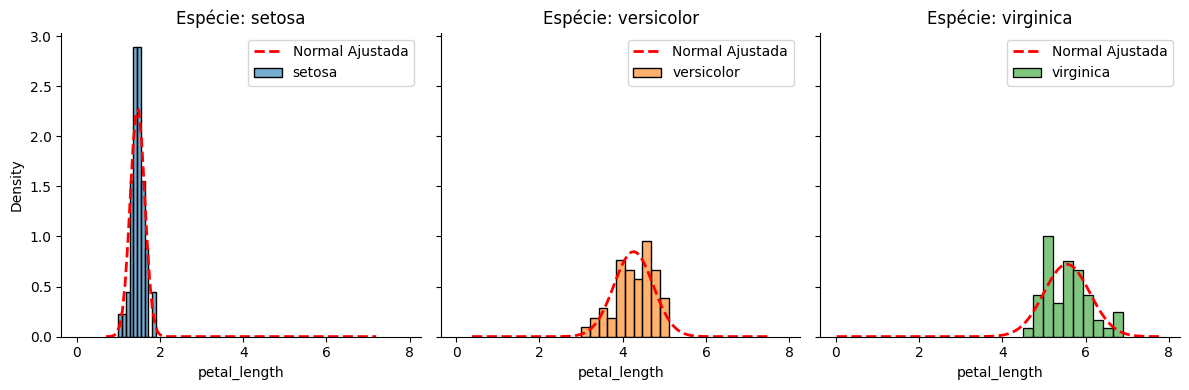

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Carregar o dataset Iris diretamente da fonte oficial especificada
url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv'
df = pd.read_csv(url)

# 4. Calcular a média e o desvio padrão para o dataset completo
mean_all = df['petal_length'].mean()
std_all = df['petal_length'].std()

print(f"Dataset Completo - Média (petal_length): {mean_all:.3f}")
print(f"Dataset Completo - Desvio Padrão (petal_length): {std_all:.3f}\n")

# Calcular média e desvio padrão separadamente para cada espécie
stats_species = df.groupby('species')['petal_length'].agg(['mean', 'std'])
print("Estatísticas por Espécie:")
print(stats_species)

# 1 e 2. Plotar o histograma de todas as 150 flores com a distribuição normal superposta
plt.figure(figsize=(10, 6))
count, bins, ignored = plt.hist(df['petal_length'], bins=15, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Dados (Histograma)')

# Gerar a curva normal teórica usando a média e desvio padrão dos dados
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, mean_all, std_all)
plt.plot(x, p, 'r--', linewidth=2, label='Distribuição Normal Ajustada')

plt.title('Distribuição do Comprimento das Pétalas (Todas as Espécies)')
plt.xlabel('Petal Length')
plt.ylabel('Densidade')
plt.legend()
plt.show()

# 3. Histogramas separados para cada uma das três espécies com normal superposta
g = sns.FacetGrid(df, col="species", hue="species", height=4, aspect=1)
g.map(sns.histplot, "petal_length", stat="density", kde=False, bins=10, alpha=0.6, edgecolor='black')

# Adicionar a curva normal em cada subgráfico
for species_name, ax in g.axes_dict.items():
    subset = df[df['species'] == species_name]['petal_length']
    mu, std = subset.mean(), subset.std()

    xmin, xmax = ax.get_xlim()
    x = np.linspace(xmin, xmax, 100)
    p = stats.norm.pdf(x, mu, std)
    ax.plot(x, p, 'r--', linewidth=2, label='Normal Ajustada')
    ax.set_title(f'Espécie: {species_name}')
    ax.legend()

plt.tight_layout()
plt.show()

## Problem 1: Exploring Petal Length

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Carregar o Iris dataset
url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv'
df = pd.read_csv(url)
df.head()

### Analysis and Discussion (Problem 1):

1. **Complete Dataset:** A clear bimodal (or multimodal) distribution is observed, with two main peaks separated by a valley. This occurs because we grouped three different species with distinct petal length characteristics. Therefore, **the normal distribution is not a good model** for the complete dataset as a whole.
2. **Setosa Species:** Shows a distribution tightly concentrated around the mean ($\approx 1.46$) with a low standard deviation ($0.17$). The normal curve fits reasonably well, although it is very narrow.
3. **Versicolor Species:** Has a mean around $4.26$ with moderate dispersion. The distribution approximates a symmetrical shape, where the normal curve works as a reasonable model.
4. **Virginica Species:** Has the highest mean ($\approx 5.55$) and the greatest variability among the three. The data distribution follows the theoretical normal curve in an acceptable manner.

## Problem 2: Correlation Between Petal Length and Petal Width

## Problem 3: Comparing Species Using t-Tests

## Problem 4: Comparing the Species Using ANOVA